# Laboratory Activity 1: Philippine Coin Detection
### Convolution, Spatial Filtering & Edge Detection

**Goal:** Select Philippine coins from the dataset whose values sum to **₱21.10**, then process
them with a classic computer-vision pipeline (grayscale → noise reduction → convolution →
edge detection → clean-up) so that:

- Coin **edges** are sharp and clearly defined
- Coin **denominations / markings** remain legible
- The **total amount (₱21.10)** can be visually verified

**Coins selected:** `20 Piso` + `1 Piso` + `10 Sentimo` = **₱21.10**

| Coin | Value |
|---|---|
| 20 Piso | ₱20.00 |
| 1 Piso | ₱1.00 |
| 10 Sentimo | ₱0.10 |
| **Total** | **₱21.10** |


## 1. Imports

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import os

%matplotlib inline

## 2. Dataset Configuration

Point `DATASET_DIR` to the folder containing your coin images, then list the coins that add
up to the target amount. Only images already present in the dataset are used — **no new
photos are captured.**

In [ ]:
DATASET_DIR = "/content/drive/MyDrive/COINS-20260815T115822Z-1-001/COINS"
COINS = [
    {"name": "20 Piso",    "value": 20.00, "file": "20.jpg"},
    {"name": "1 Piso",     "value": 1.00,  "file": "Philippine peso - Wikiwand.jpeg"},
    {"name": "10 Sentimo", "value": 0.10,  "file": "File_2009phil10centobv_jpg - Wikimedia Commons.jpeg"},
]

for c in COINS:
    c["path"] = os.path.join(DATASET_DIR, c["file"])

TOTAL = sum(c["value"] for c in COINS)
TILE = 420

print("Selected coins:")
for c in COINS:
    print(f"  {c['name']:<12} PHP {c['value']:.2f}   ({c['path']})")
print(f"\nTOTAL = PHP {TOTAL:.2f}")

Selected coins:
  20 Piso      PHP 20.00   (/content/drive/MyDrive/COINS-20260815T115822Z-1-001/COINS/20.jpg)
  1 Piso       PHP 1.00   (/content/drive/MyDrive/COINS-20260815T115822Z-1-001/COINS/Philippine peso - Wikiwand.jpeg)
  10 Sentimo   PHP 0.10   (/content/drive/MyDrive/COINS-20260815T115822Z-1-001/COINS/File_2009phil10centobv_jpg - Wikimedia Commons.jpeg)

TOTAL = PHP 21.10


## 3. Helper — Load & Center-Crop Each Coin

In [ ]:
def load_square(path, size=TILE):
    """Load an image, center-crop it to a square, and resize."""
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    s = min(h, w)
    y0, x0 = (h - s) // 2, (w - s) // 2
    img = img[y0:y0 + s, x0:x0 + s]
    img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    return img

## 4. Stage 1 — Load & Display the Selected Coins

This is the **original combined coin image**: the raw photos of the 3 coins, cropped to
squares and placed side by side.

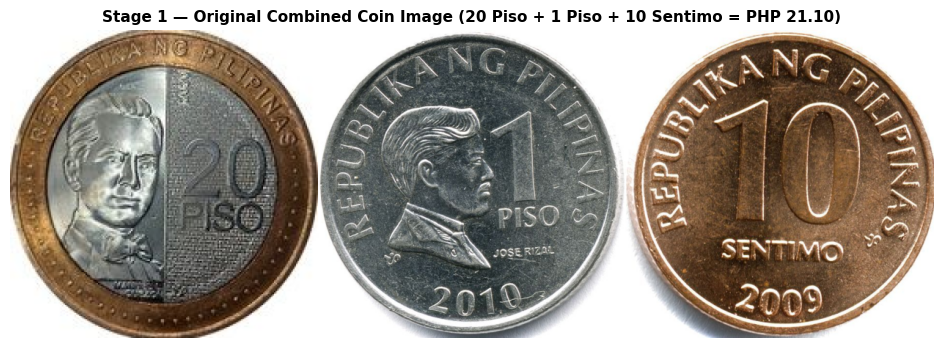

In [ ]:
originals = [load_square(c["path"]) for c in COINS]
combined_original = np.hstack(originals)

plt.figure(figsize=(12, 4))
plt.imshow(combined_original)
plt.title("Stage 1 — Original Combined Coin Image (20 Piso + 1 Piso + 10 Sentimo = PHP 21.10)",
          fontsize=11, fontweight="bold")
plt.axis("off")
plt.show()

## 5. Stage 2 — Pre-Processing: Grayscale + Noise Reduction

1. **Grayscale conversion** — reduces the image to a single intensity channel, which
   convolution / edge-detection filters operate on.
2. **Median filter** — removes salt-and-pepper style noise while preserving edges.
3. **Gaussian blur** — smooths remaining high-frequency noise so Canny edge detection
   later doesn't pick up texture noise from the coin's metal surface.

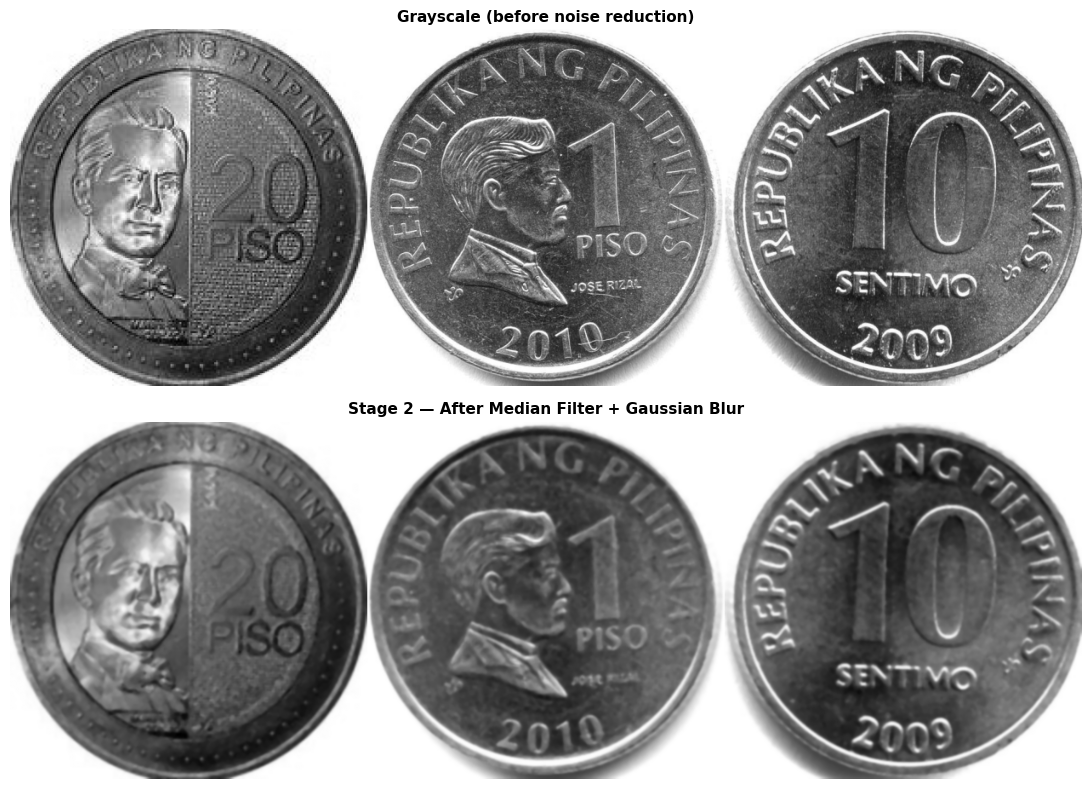

In [ ]:
def grayscale_denoise(img_rgb):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    median = cv2.medianBlur(gray, 5)
    gauss = cv2.GaussianBlur(median, (5, 5), 1.0)
    return gray, median, gauss

denoise_stack = [grayscale_denoise(im) for im in originals]
gray_imgs     = [d[0] for d in denoise_stack]
median_imgs   = [d[1] for d in denoise_stack]
filtered_imgs = [d[2] for d in denoise_stack]

combined_gray     = np.hstack(gray_imgs)
combined_filtered = np.hstack(filtered_imgs)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
axes[0].imshow(combined_gray, cmap="gray")
axes[0].set_title("Grayscale (before noise reduction)", fontsize=11, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(combined_filtered, cmap="gray")
axes[1].set_title("Stage 2 — After Median Filter + Gaussian Blur", fontsize=11, fontweight="bold")
axes[1].axis("off")
plt.tight_layout()
plt.show()


## 6. Stage 3 — Convolution (Sharpening Kernel)

A 3×3 **sharpening kernel** is convolved over each denoised grayscale image using
`cv2.filter2D`. This emphasizes edges and fine details (like the coin's engraved text)
before edge detection is applied.

$$
K = \begin{bmatrix} 0 & -1 & 0 \\ -1 & 5 & -1 \\ 0 & -1 & 0 \end{bmatrix}
$$

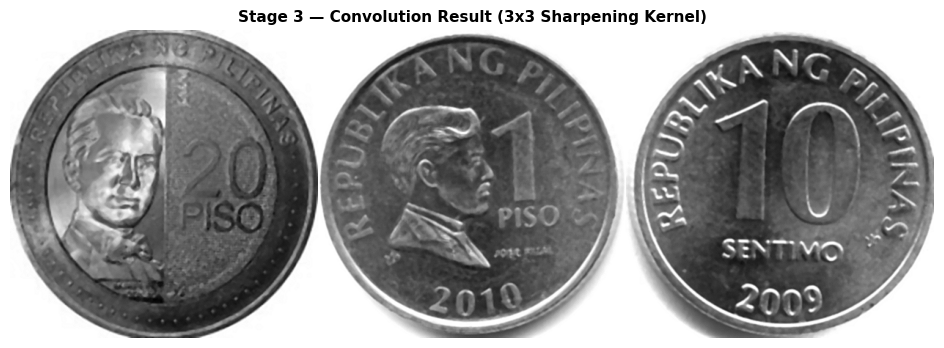

In [ ]:
sharpen_kernel = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)

def convolve_sharpen(gray_img, kernel=sharpen_kernel):
    return cv2.filter2D(gray_img, -1, kernel)

sharpened_imgs = [convolve_sharpen(g) for g in filtered_imgs]
combined_sharpened = np.hstack(sharpened_imgs)

plt.figure(figsize=(12, 4))
plt.imshow(combined_sharpened, cmap="gray")
plt.title("Stage 3 — Convolution Result (3x3 Sharpening Kernel)", fontsize=11, fontweight="bold")
plt.axis("off")
plt.show()


## 7. Stage 4 — Edge Detection (Canny)

The **Canny edge detector** (built on Sobel gradi8ents + non-max suppression + hysteresis
thresholding) is applied to the sharpened image. Thresholds are computed **adaptively**
from each coin's median pixel intensity so the same code works across coins of different
color/brightness (copper 10-sentimo vs. bi-metal 20-piso vs. silver 1-piso).

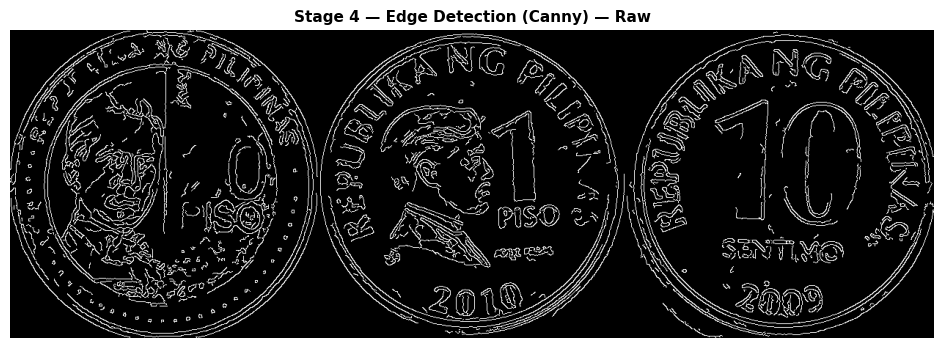

In [ ]:
def canny_edges(sharp_img, sigma=0.33):
    v = np.median(sharp_img)
    lower = int(max(0, (1.0 - sigma) * v))
    upper = int(min(255, (1.0 + sigma) * v))
    return cv2.Canny(sharp_img, lower, upper)

raw_edges = [canny_edges(s) for s in sharpened_imgs]
combined_raw_edges = np.hstack(raw_edges)

plt.figure(figsize=(12, 4))
plt.imshow(combined_raw_edges, cmap="gray")
plt.title("Stage 4 — Edge Detection (Canny) — Raw", fontsize=11, fontweight="bold")
plt.axis("off")
plt.show()


## 8. Stage 5 - Clean up

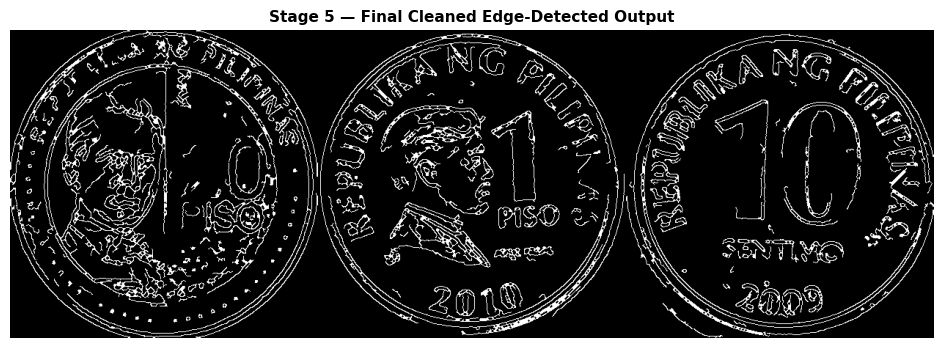

In [ ]:
def clean_edges(edge_img, min_area=15):
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    closed = cv2.morphologyEx(edge_img, cv2.MORPH_CLOSE, kernel, iterations=1)

    n, labels, stats, _ = cv2.connectedComponentsWithStats(closed, connectivity=8)
    clean = np.zeros_like(closed)
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] >= min_area:
            clean[labels == i] = 255
    return clean

clean_imgs = [clean_edges(e) for e in raw_edges]
combined_clean = np.hstack(clean_imgs)

plt.figure(figsize=(12, 4))
plt.imshow(combined_clean, cmap="gray")
plt.title("Stage 5 — Final Cleaned Edge-Detected Output", fontsize=11, fontweight="bold")
plt.axis("off")
plt.show()


## 9. Final Annotated Result — Visual Total Verification

Colorize the cleaned edge map, label each coin with its name and value, and print a
running total footer so the ₱21.10 amount can be **visually verified**.

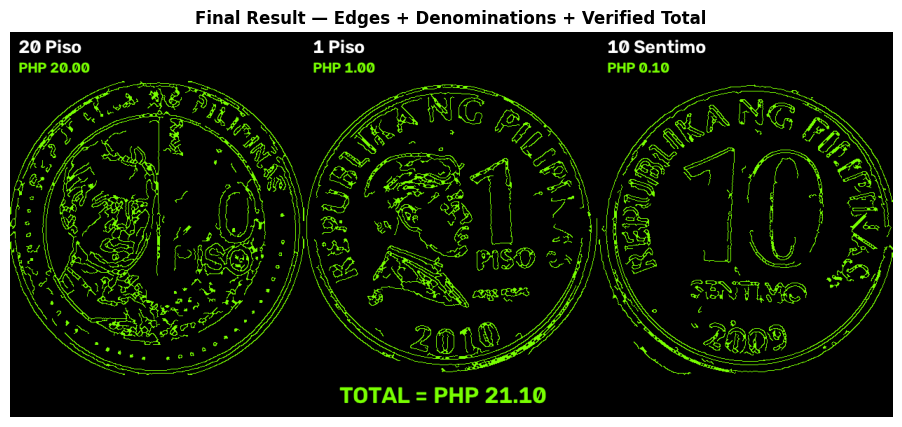

In [ ]:
def make_final_panel(clean_imgs, coins):
    panels = []
    running = 0.0
    for img, c in zip(clean_imgs, coins):
        running += c["value"]
        panel = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
        mask = img > 0
        panel[mask] = (0, 255, 120)

        bar = np.zeros((70, panel.shape[1], 3), dtype=np.uint8)
        cv2.putText(bar, c["name"], (12, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.9,
                    (255, 255, 255), 2, cv2.LINE_AA)
        cv2.putText(bar, f"PHP {c['value']:.2f}", (12, 58), cv2.FONT_HERSHEY_SIMPLEX, 0.7,
                    (0, 255, 120), 2, cv2.LINE_AA)
        panels.append(np.vstack([bar, panel]))

    combined = np.hstack(panels)
    footer = np.zeros((60, combined.shape[1], 3), dtype=np.uint8)
    cv2.putText(footer, f"TOTAL = PHP {running:.2f}",
                (combined.shape[1] // 2 - 160, 40),
                cv2.FONT_HERSHEY_SIMPLEX, 1.1, (0, 255, 120), 3, cv2.LINE_AA)
    return np.vstack([combined, footer])

final_annotated = make_final_panel(clean_imgs, COINS)

plt.figure(figsize=(12, 5))
plt.imshow(cv2.cvtColor(final_annotated, cv2.COLOR_BGR2RGB))
plt.title("Final Result — Edges + Denominations + Verified Total", fontsize=12, fontweight="bold")
plt.axis("off")
plt.show()


## 10. Full Pipeline Summary (All Stages in One Figure)

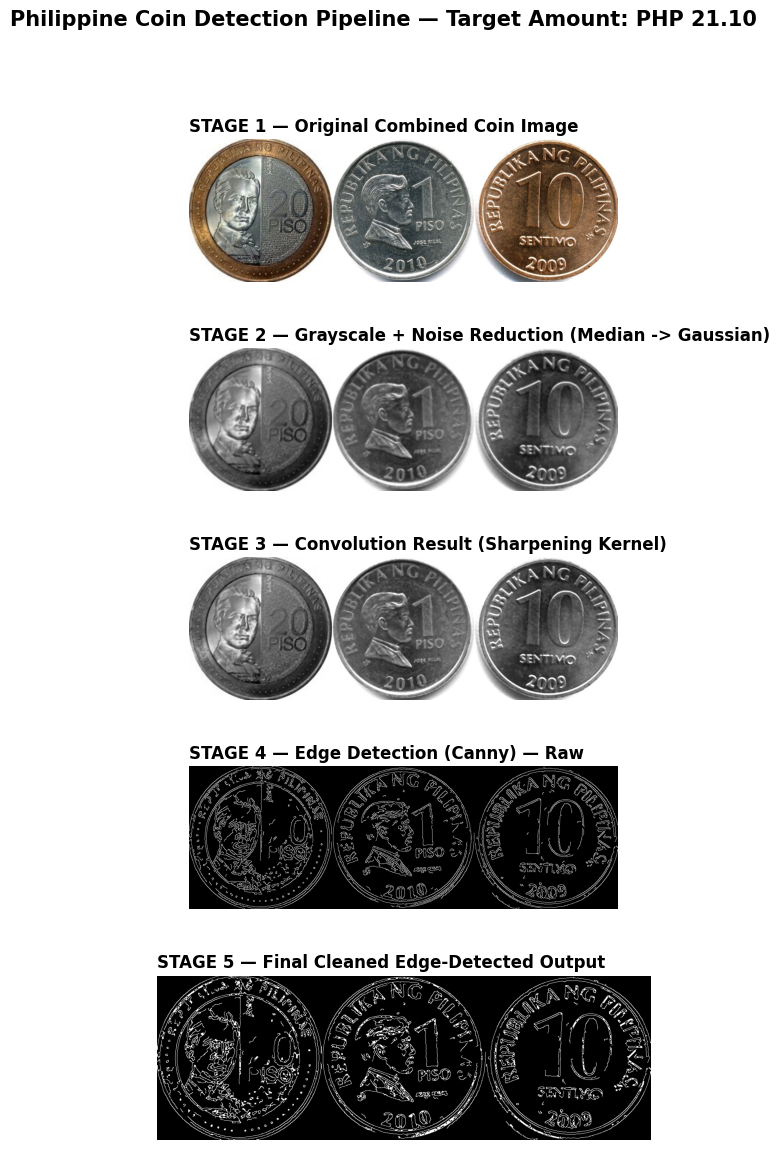

In [ ]:
fig = plt.figure(figsize=(16, 13))
gs = gridspec.GridSpec(5, 1, height_ratios=[1, 1, 1, 1, 1.15], hspace=0.45)

titles = [
    "STAGE 1 — Original Combined Coin Image",
    "STAGE 2 — Grayscale + Noise Reduction (Median -> Gaussian)",
    "STAGE 3 — Convolution Result (Sharpening Kernel)",
    "STAGE 4 — Edge Detection (Canny) — Raw",
    "STAGE 5 — Final Cleaned Edge-Detected Output",
]
imgs_for_fig = [combined_original, combined_filtered, combined_sharpened,
                combined_raw_edges, combined_clean]

for i, (title, im) in enumerate(zip(titles, imgs_for_fig)):
    ax = fig.add_subplot(gs[i])
    cmap = None if im.ndim == 3 else "gray"
    ax.imshow(im, cmap=cmap)
    ax.set_title(title, fontsize=12, fontweight="bold", loc="left")
    ax.axis("off")

fig.suptitle(f"Philippine Coin Detection Pipeline — Target Amount: PHP {TOTAL:.2f}",
             fontsize=15, fontweight="bold")
plt.show()


## 11. Save All Deliverables

In [ ]:
OUTPUT_DIR = "./outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

cv2.imwrite(f"{OUTPUT_DIR}/1_original_combined.png", cv2.cvtColor(combined_original, cv2.COLOR_RGB2BGR))
cv2.imwrite(f"{OUTPUT_DIR}/2_grayscale_filtered.png", combined_filtered)
cv2.imwrite(f"{OUTPUT_DIR}/3_convolution_sharpened.png", combined_sharpened)
cv2.imwrite(f"{OUTPUT_DIR}/4_edge_detected_final.png", combined_clean)
cv2.imwrite(f"{OUTPUT_DIR}/5_final_annotated_result.png", final_annotated)
fig.savefig(f"{OUTPUT_DIR}/0_full_pipeline_summary.png", dpi=150, bbox_inches="tight")

print("Saved deliverables to:", OUTPUT_DIR)
print(f"Verified total: PHP {TOTAL:.2f}")


Saved deliverables to: ./outputs
Verified total: PHP 21.10
